# APA - Lista de Problemas 2: Problema Individual 4

##  La dura vida del estudiante

In [30]:
# Descomentar para actualizar librerias
# Si se actualiza alguna libreria hay que reiniciar el notebook
# !pip install pandas --upgrade  --quiet
# !pip install numpy --upgrade  --quiet
# !pip install scipy --upgrade  --quiet
# !pip install statsmodels --upgrade  --quiet
# !pip install scikit-learn --upgrade  --quiet
!pip install missingno --upgrade  --quiet
!pip install apafib --upgrade --quiet

In [ ]:
from IPython.core.interactiveshell import InteractiveShell
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split,  KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from yellowbrick.regressor import residuals_plot, prediction_error
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
InteractiveShell.ast_node_interactivity = "all"

from time import time
from datetime import timedelta
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pandas.plotting import scatter_matrix
init_time = time()

In [32]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.precision', 3)

## APARTADO A

### CARGA DE DATOS Y VISUALIZACIÓN

Cargamos los datos y separamos la variable objetivo (Stress Label) del conjunto de datos.

In [33]:
from apafib import load_stress

# Cargamos el DataFrame
data = load_stress()

# Separamos la variable objetivo del conjunto de datos
X = data.drop(columns=['Stress Label'])
y = data['Stress Label']

X.head()

,1. Age,2. Gender,5. Academic Year,6. Current CGPA,7. Did you receive a waiver or scholarship at your university?,"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?","2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?","3. In a semester, how often you felt nervous and stressed because of academic pressure?","4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)","5. In a semester, how often you felt confident about your ability to handle your academic / university problems?","6. In a semester, how often you felt as if things in your academic life is going on your way?","7. In a semester, how often are you able to control irritations in your academic / university affairs?","8. In a semester, how often you felt as if your academic performance was on top?","9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?","10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?"
0,18-22,Female,Fourth Year or Equivalent,2.50 - 2.99,No,2,2,3,2,2,2,2,2,2,2
1,18-22,Male,First Year or Equivalent,3.80 - 4.00,No,2,2,2,2,2,2,2,1,1,2
2,18-22,Male,First Year or Equivalent,3.00 - 3.39,No,3,2,2,3,3,2,3,2,2,1
3,18-22,Male,First Year or Equivalent,3.40 - 3.79,No,2,2,2,2,2,2,2,2,2,2
4,18-22,Male,First Year or Equivalent,3.40 - 3.79,No,2,2,2,2,2,2,2,2,2,2


In [34]:
X.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
1. Age,1977,5,18-22,1273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2. Gender,1977,3,Male,1372,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5. Academic Year,1977,5,First Year or Equivalent,592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6. Current CGPA,1977,6,3.00 - 3.39,572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7. Did you receive a waiver or scholarship at your university?,1977,2,No,1571,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?",1977.0,NaN,NaN,NaN,2.342,1.179,0.0,2.0,2.0,3.0,4.0
"2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?",1977.0,NaN,NaN,NaN,2.32,1.155,0.0,2.0,2.0,3.0,4.0
"3. In a semester, how often you felt nervous and stressed because of academic pressure?",1977.0,NaN,NaN,NaN,2.706,1.135,0.0,2.0,3.0,4.0,4.0
"4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)",1977.0,NaN,NaN,NaN,2.361,1.224,0.0,2.0,2.0,3.0,4.0
"5. In a semester, how often you felt confident about your ability to handle your academic / university problems?",1977.0,NaN,NaN,NaN,1.825,1.085,0.0,1.0,2.0,2.0,4.0


Podemos mirar como se distribuyen los 3 valores de la variable objetivo en el conjunto de datos:

In [35]:
y.value_counts()

Stress Label
Moderate Stress          1316
High Perceived Stress     546
Low Stress                115
Name: count, dtype: int64

Vemos que más de la mitad de los estudiantes (un 66%) sufre un nivel de estrés medio, un 27% sufre un nivel de estrés alto y tan solo un 7% de los estudiantes sufre poco estrés.

Antes de hacer cualquier estudio de los datos miramos si hay valores perdidos:

In [36]:
X.isna().sum()

1. Age                                                                                                                                        0
2. Gender                                                                                                                                     0
5. Academic Year                                                                                                                              0
6. Current CGPA                                                                                                                               0
7. Did you receive a waiver or scholarship at your university?                                                                                0
1. In a semester, how often have you felt upset due to something that happened in your academic affairs?                                      0
2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?                        

Vemos que no hay valores perdidos que tengamos que imputar.

### División entrenamiento y test
Particionamos los datos en conjunto de entrenamiento y conjunto de test (70% y 30% respectivamente). 

Tal y como se especifica en el enunciado usaremos una partición estratificada, para que haya aproximadamente la misma proporción de ejemplos de cada clase en cada partición y fijaremos el `random_state` con un valor distinto de cero para la reproducibilidad.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

En el conjunto de datos que hemos visto antes, se puede observar que hay un conjunto de variables que son categóricas. A continuación, generaremos dos conjuntos de datos, uno en el que usemos la codificación numérica de las variables categóricas y otro en el que binarizemos las variables.

Primero identificamos las columnas categóricas que necesitan transformación mediante:

In [38]:
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
print(cat_cols)

Index(['1. Age', '2. Gender', '5. Academic Year', '6. Current CGPA',
       '7. Did you receive a waiver or scholarship at your university?'],
      dtype='object')


Para transformar el primer cojunto (codificación númerica) codificamos las categorías de estas variables en números secuenciales. Para ello definimos un diccionario para cada una de las 5 variables para mantener el orden lógico.

In [ ]:
# Creamos copias para preservar los datos originales
X_train_num = X_train.copy()
X_test_num = X_test.copy()

age_map = {'18-22': 0, '23-26': 1, '27-30': 2}
gender_map = {'Female': 0, 'Male': 1, 'Prefer not to say': 2}
year_map = {'First Year or Equivalent': 0, 'Second Year or Equivalent': 1, 
            'Third Year or Equivalent': 2, 'Fourth Year or Equivalent': 3, 'Other': 4}
cgpa_map = {'2.50 - 2.99': 0, '3.00 - 3.39': 1, '3.40 - 3.79': 2, '3.80 - 4.00': 3, 'Other': 4}
scholarship_map = {'No': 0, 'Yes': 1} 

# Aplicamos el mapeo a los conjuntos
for df in [X_train_num, X_test_num]:
    df['1. Age'] = df['1. Age'].map(age_map)
    df['2. Gender'] = df['2. Gender'].map(gender_map)
    df['5. Academic Year'] = df['5. Academic Year'].map(year_map)
    df['6. Current CGPA'] = df['6. Current CGPA'].map(cgpa_map)
    df['7. Did you receive a waiver or scholarship at your university?'] = df['7. Did you receive a waiver or scholarship at your university?'].map(scholarship_map)

X_train_num.head()

,1. Age,2. Gender,5. Academic Year,6. Current CGPA,7. Did you receive a waiver or scholarship at your university?,"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?","2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?","3. In a semester, how often you felt nervous and stressed because of academic pressure?","4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)","5. In a semester, how often you felt confident about your ability to handle your academic / university problems?","6. In a semester, how often you felt as if things in your academic life is going on your way?","7. In a semester, how often are you able to control irritations in your academic / university affairs?","8. In a semester, how often you felt as if your academic performance was on top?","9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?","10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?"
1660,0.0,0,1,1.0,0,4,4,4,4,3,3,2,4,4,4
1513,0.0,0,2,3.0,0,4,3,4,4,3,3,3,3,3,4
709,1.0,1,3,1.0,0,2,2,2,1,1,0,2,1,2,2
1964,1.0,0,3,0.0,0,4,4,4,4,0,0,0,0,4,4
1016,0.0,1,0,4.0,0,2,2,3,2,2,2,3,2,0,1


Podemos observar que las 5 variables categóricas han sido transformadas correctamente.

A continuación generamos el segundo conjunto de datos con variables binarizadas aplicando One-Hot Encoding.

In [41]:
X_train_bin = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_bin = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

# Alinear las columnas del conjunto de test con las de entrenamiento.
X_train_bin, X_test_bin = X_train_bin.align(X_test_bin, join='left', axis=1, fill_value=0)
X_train_bin.head()

,"1. In a semester, how often have you felt upset due to something that happened in your academic affairs?","2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?","3. In a semester, how often you felt nervous and stressed because of academic pressure?","4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams)","5. In a semester, how often you felt confident about your ability to handle your academic / university problems?","6. In a semester, how often you felt as if things in your academic life is going on your way?","7. In a semester, how often are you able to control irritations in your academic / university affairs?","8. In a semester, how often you felt as if your academic performance was on top?","9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control?","10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them?",1. Age_23-26,1. Age_27-30,1. Age_Above 30,1. Age_Below 18,2. Gender_Male,2. Gender_Prefer not to say,5. Academic Year_Fourth Year or Equivalent,5. Academic Year_Other,5. Academic Year_Second Year or Equivalent,5. Academic Year_Third Year or Equivalent,6. Current CGPA_3.00 - 3.39,6. Current CGPA_3.40 - 3.79,6. Current CGPA_3.80 - 4.00,6. Current CGPA_Below 2.50,6. Current CGPA_Other,7. Did you receive a waiver or scholarship at your university?_Yes
1660,4,4,4,4,3,3,2,4,4,4,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0
1513,4,3,4,4,3,3,3,3,3,4,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
709,2,2,2,1,1,0,2,1,2,2,1,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0
1964,4,4,4,4,0,0,0,0,4,4,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1016,2,2,3,2,2,2,3,2,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0


Las cinco variables categóricas han sido binrizadas correctamente.


Ahora podemos pasar a hacer una visualización mínima de las variables, empezando con un heatmap para ver las correlaciones entre ellas.

<Figure size 1400x1000 with 0 Axes>

<Axes: >

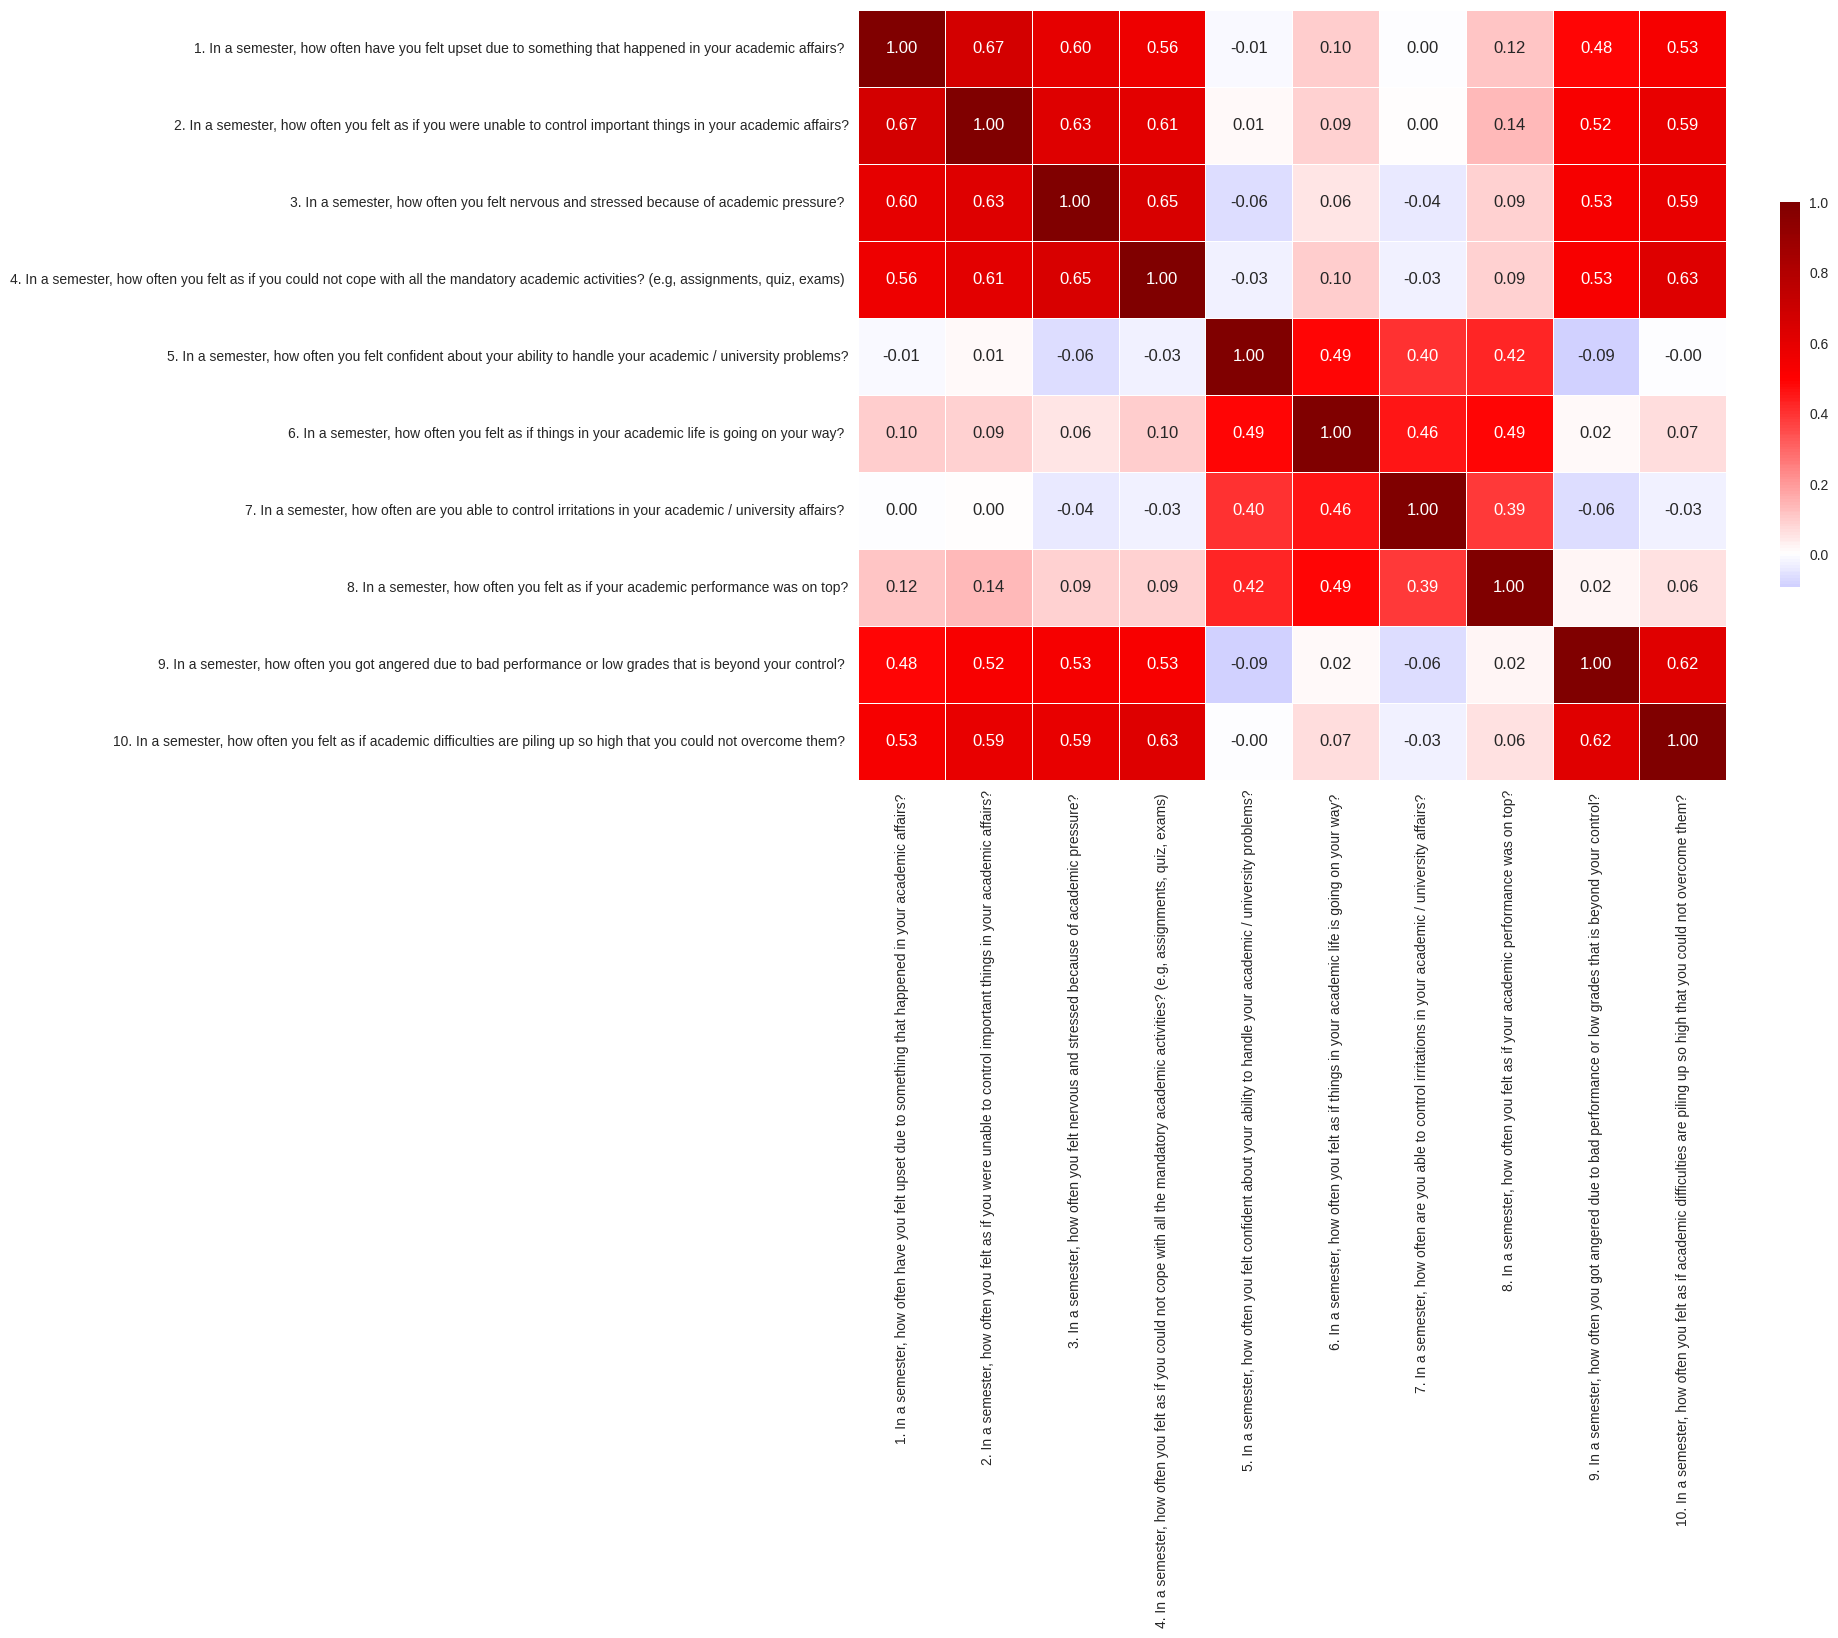

In [ ]:
plt.figure(figsize=(14, 10))
corr_matrix = X_train.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='seismic', center=0, fmt=".2f",
            linewidths=.5, cbar_kws={"shrink": .5})
plt.show()